# Preps

In [32]:
import pandas as pd
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt
import os
import glob
import numpy as np


curfolder = os.getcwd()


# load the distances 
dist = pd.read_csv('distances_hand_learners.csv', index_col=0)

In [33]:
# get rid of all cols that includes speed, acc or jerk
dist = dist.loc[:,~dist.columns.str.contains('speed|acceleration|jerk|velocity')]

# list all the columns
allcols = dist.columns
allcols

# keep only columns that contain _y, _z, _x
dimcols = [col for col in allcols if '_x' in col or '_y' in col or '_z' in col]
# get also rid of wri_hip, and wri_nose cols
dimcols = [col for col in dimcols if 'wri_hip' not in col and 'wri_nose' not in col]

# keep only columns that do not contain _y, _z, _x
nondimcols = [col for col in allcols if '_x' not in col and '_y' not in col and '_z' not in col]
# and get rid of the fileID and time
nondimcols = [col for col in nondimcols if col not in ['fileID', 'time']]
# get also rid of wri_hip, and wri_nose cols
nondimcols = [col for col in nondimcols if 'wri_hip' not in col and 'wri_nose' not in col]

# create a list of unique fileID
fileIDs = dist['fileID'].unique()

# PCA function

In [27]:
def get_PCA(df):
    # Step 1: Standardize the Data
    scaler = StandardScaler()
    standardized_data = scaler.fit_transform(df)
    
    # Step 2: Apply PCA
    pca = PCA()
    pca.fit(standardized_data)
    
    # Step 3: Explained Variance
    explained_variance = pca.explained_variance_ratio_
    cumulative_explained_variance = explained_variance.cumsum()

    # Step 4: Find the number of components that explain 95% variance
    n_components_for_80_variance = np.argmax(cumulative_explained_variance >= 0.8) + 1
    
    # Step 5: Compute the slope for the first n_components_for_95_variance
    if n_components_for_80_variance > 1:
        slope_80 = (cumulative_explained_variance[n_components_for_80_variance-1] - cumulative_explained_variance[0]) / (n_components_for_80_variance - 1)
    else:
        slope_80 = cumulative_explained_variance[0]  # Only one component case

    # 95% variance
    n_components_for_95_variance = np.argmax(cumulative_explained_variance >= 0.95) + 1
    
    # Step 5: Compute the slope for the first n_components_for_95_variance
    if n_components_for_95_variance > 1:
        slope_95 = (cumulative_explained_variance[n_components_for_95_variance-1] - cumulative_explained_variance[0]) / (n_components_for_95_variance - 1)
    else:
        slope_95 = cumulative_explained_variance[0]  # Only one component case


    #Optionally plot the cumulative explained variance
    # plt.figure(figsize=(8, 6))
    # plt.plot(cumulative_explained_variance, marker='o', label='Cumulative Explained Variance')
    # plt.axvline(x=n_components_for_80_variance-1, color='red', linestyle='--', label=f'80% Variance at {n_components_for_80_variance} components')
    # plt.axvline(x=n_components_for_95_variance-1, color='green', linestyle='--', label=f'95% Variance at {n_components_for_95_variance} components')
    # plt.xlabel('Number of Principal Components')
    # plt.ylabel('Cumulative Explained Variance')
    # plt.title('Cumulative Explained Variance by PCA')
    # plt.grid(True)
    # plt.legend()
    # plt.show()

    return n_components_for_80_variance, slope_80, n_components_for_95_variance, slope_95




# Complexity

In [34]:
# length of the fileIDs
len(fileIDs)

# from the list, get away anything that contains GtST
#fileIDs = [fileID for fileID in fileIDs if 'GtST' not in fileID]

fileIDs

array(['LP30_02_TREPPE_hands_world', 'LP18_02_ABLEHNEN_hands_world',
       'LP38_01_TEE_hands_world', ..., 'LP40_01_KAUFEN_hands_world',
       'LP19_01_TRINKEN_hands_world', 'LP30_02_STECKER_hands_world'],
      dtype=object)

## PCA with dimension-cols

In [7]:
# pick one random fileID
fileID = fileIDs[10]

# filter the dataframe for the fileID
subdf = dist[dist['fileID'] == fileID]

# and keep only cols
subdf = subdf[dimcols]

# use the function
n_components_80, slope_80, n_components_95, slope_95 = get_PCA(subdf)

print(n_components_80, slope_80, n_components_95, slope_95)

4 0.13324803316065106 7 0.0870249409030009


## PCA with non-dimension cols

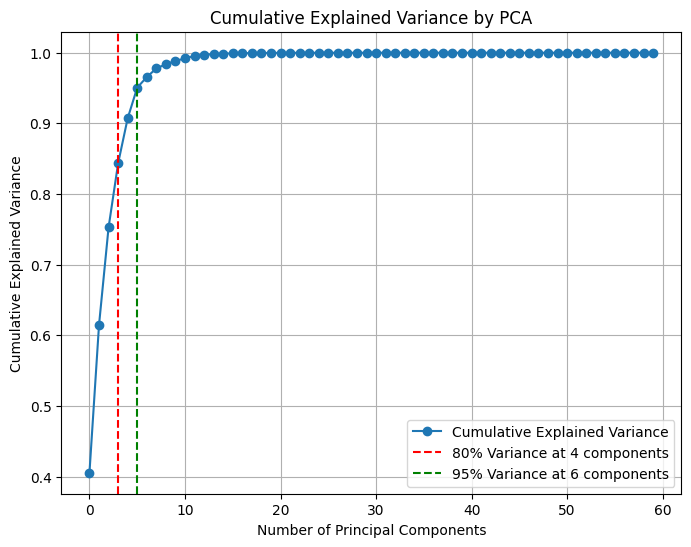

4 0.14595180929036725 6 0.10899868364526388


In [10]:
# pick one random fileID
fileID = fileIDs[50]

# filter the dataframe for the fileID
subdf = dist[dist['fileID'] == fileID]

# and keep only cols
subdf = subdf[nondimcols]

# use the function
n_components_80, slope_80, n_components_95, slope_95 = get_PCA(subdf)

print(n_components_80, slope_80, n_components_95, slope_95)

## Loop and extract for all files

In [36]:
# prepare empty df
pca = pd.DataFrame()

for id in fileIDs:
    subdf = dist[dist['fileID'] == id]
    # perform pca on dimensions
    subdf = subdf[dimcols]
    # get rid of nan values
    subdf = subdf.dropna()
    # if the subdf is empty, continue
    if subdf.empty:
        continue
    dim_n_components_80, dim_slope_80, dim_n_components_95, dim_slope_95 = get_PCA(subdf)

    # perform pca on non-dimensions
    subdf = dist[dist['fileID'] == id]
    subdf = subdf[nondimcols]
    # drop nan values
    subdf = subdf.dropna()
    nondim_n_components_80, nondim_slope_80, nondim_n_components_95, nondim_slope_95 = get_PCA(subdf)

    # create a row
    row = pd.DataFrame({'fileID': id, 'dim_n_components_80': dim_n_components_80, 'dim_slope_80': dim_slope_80, 'dim_n_components_95': dim_n_components_95, 'dim_slope_95': dim_slope_95, 'nondim_n_components_80': nondim_n_components_80, 'nondim_slope_80': nondim_slope_80, 'nondim_n_components_95': nondim_n_components_95, 'nondim_slope_95': nondim_slope_95}, index=[0])

    # concat row and df
    pca = pd.concat([pca, row], ignore_index=True)

    
    

c:\Users\Sarka Kadava\.conda\envs\EffortProject\Lib\site-packages\sklearn\decomposition\_pca.py:591: RuntimeWarning: invalid value encountered in divide
  explained_variance_ = (S**2) / (n_samples - 1)
c:\Users\Sarka Kadava\.conda\envs\EffortProject\Lib\site-packages\sklearn\decomposition\_pca.py:591: RuntimeWarning: invalid value encountered in divide
  explained_variance_ = (S**2) / (n_samples - 1)
c:\Users\Sarka Kadava\.conda\envs\EffortProject\Lib\site-packages\sklearn\decomposition\_pca.py:591: RuntimeWarning: invalid value encountered in divide
  explained_variance_ = (S**2) / (n_samples - 1)
c:\Users\Sarka Kadava\.conda\envs\EffortProject\Lib\site-packages\sklearn\decomposition\_pca.py:591: RuntimeWarning: invalid value encountered in divide
  explained_variance_ = (S**2) / (n_samples - 1)
c:\Users\Sarka Kadava\.conda\envs\EffortProject\Lib\site-packages\sklearn\decomposition\_pca.py:591: RuntimeWarning: invalid value encountered in divide
  explained_variance_ = (S**2) / (n_sam

In [37]:
pca

,fileID,dim_n_components_80,dim_slope_80,dim_n_components_95,dim_slope_95,nondim_n_components_80,nondim_slope_80,nondim_n_components_95,nondim_slope_95
0,LP30_02_TREPPE_hands_world,4,0.107722,8,0.062338,3,0.131674,6,0.079030
1,LP18_02_ABLEHNEN_hands_world,6,0.104431,13,0.054548,5,0.120642,9,0.074129
2,LP15_01_PFANNE_hands_world,5,0.119777,9,0.076820,4,0.141647,7,0.090977
3,LP19_01_BABY_hands_world,5,0.107394,11,0.055332,5,0.132494,8,0.089744
4,LP29_01_JUCKEN_hands_world,5,0.110229,9,0.071045,4,0.133522,7,0.089325
...,...,...,...,...,...,...,...,...,...
2350,LP18_01_SPINNE_hands_world,5,0.123411,9,0.075592,3,0.195230,7,0.086769
2351,LP38_01_NAEHEN_hands_world,4,0.155211,7,0.095898,3,0.205167,5,0.131965
2352,LP40_01_KAUFEN_hands_world,4,0.138795,7,0.086656,3,0.163386,6,0.093566
2353,LP19_01_TRINKEN_hands_world,4,0.148894,9,0.072571,4,0.171214,8,0.094731


In [38]:
# save the pca
pca.to_csv('pca_hand_learners.csv', index=False)

## motor complexity only for hand